In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

In [3]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
orders = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_orders_clean.csv"
)

events = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_app_events_clean.csv"
)

orders["order_date"] = pd.to_datetime(orders["order_date"])
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"])

print("Orders:", orders.shape)
print("Events:", events.shape)

Orders: (3600, 17)
Events: (12000, 12)


In [5]:
order_statistics = orders["net_amount_inr"].describe()

display(order_statistics)

count     3600.000000
mean      1643.287222
std       1412.796659
min        263.540000
25%        669.125000
50%       1231.750000
75%       2087.757500
max      14844.950000
Name: net_amount_inr, dtype: float64

In [6]:
revenue_stats = {
    "Mean": orders["net_amount_inr"].mean(),
    "Median": orders["net_amount_inr"].median(),
    "Mode": orders["net_amount_inr"].mode()[0],
    "Standard Deviation": orders["net_amount_inr"].std(),
    "Variance": orders["net_amount_inr"].var(),
    "Skewness": orders["net_amount_inr"].skew(),
    "Kurtosis": orders["net_amount_inr"].kurt()
}

display(pd.DataFrame(
    revenue_stats.items(),
    columns=["Statistic", "Value"]
))

,Statistic,Value
0,Mean,1.643287e+03
1,Median,1.231750e+03
2,Mode,5.951400e+02
3,Standard Deviation,1.412797e+03
4,Variance,1.995994e+06
5,Skewness,2.432157e+00
6,Kurtosis,9.270443e+00


the revenue distribution

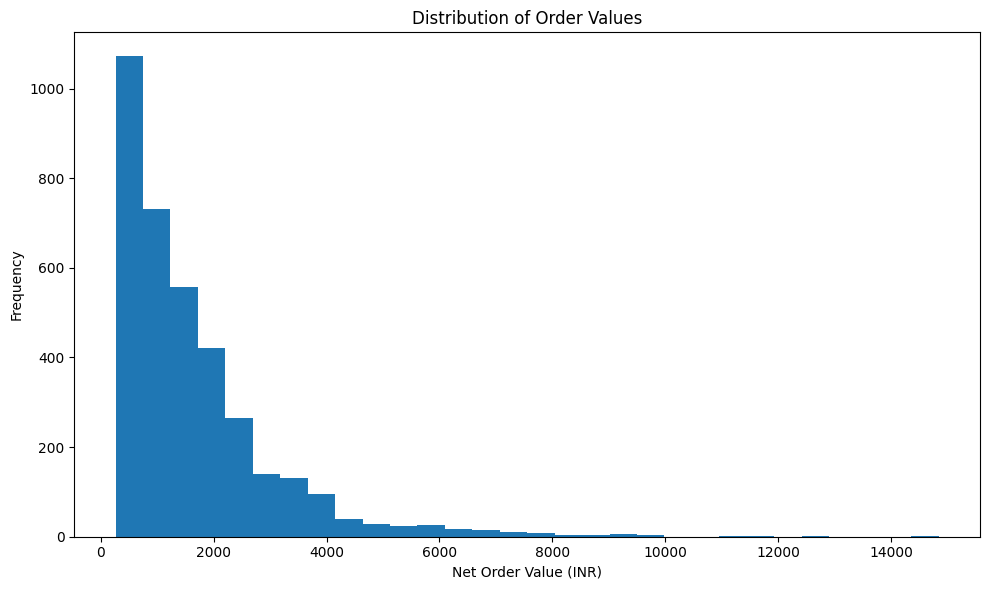

In [7]:
plt.figure(figsize=(10, 6))

plt.hist(
    orders["net_amount_inr"],
    bins=30
)

plt.title("Distribution of Order Values")
plt.xlabel("Net Order Value (INR)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Boxplot and outlier investigation

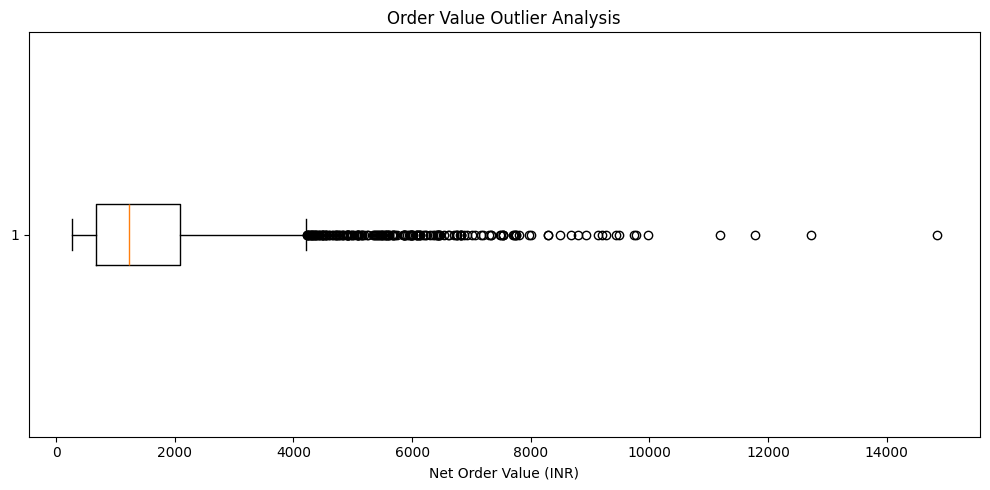

In [8]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    orders["net_amount_inr"],
    vert=False
)

plt.title("Order Value Outlier Analysis")
plt.xlabel("Net Order Value (INR)")

plt.tight_layout()
plt.show()

In [9]:
Q1 = orders["net_amount_inr"].quantile(0.25)
Q3 = orders["net_amount_inr"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = orders[
    (orders["net_amount_inr"] < lower_limit)
    | (orders["net_amount_inr"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))

Q1: 669.125
Q3: 2087.7575
IQR: 1418.6325000000002
Lower limit: -1458.8237500000005
Upper limit: 4215.706250000001
Number of outliers: 179


category-level statistics

In [10]:
category_stats = (
    orders.groupby("category")["net_amount_inr"]
    .agg(
        ["count", "mean", "median", "std"]
    )
    .reset_index()
)

display(category_stats.round(2))

,category,count,mean,median,std
0,Beauty,449,747.40,617.24,367.90
1,Books,509,776.50,672.58,450.51
2,Electronics,734,2282.76,1892.16,1183.14
3,Fashion,695,1773.34,1410.54,1292.63
4,Home & Kitchen,743,1964.83,991.36,2049.16
5,Sports,470,1738.56,1591.98,1114.62


Hypothesis Testing

In [11]:
category_groups = [
    group["net_amount_inr"].values
    for _, group in orders.groupby("category")
]

In [12]:
f_statistic, p_value = stats.f_oneway(
    *category_groups
)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: At least one category mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

F-statistic: 134.99249726717545
P-value: 1.752093301753502e-131
Reject H0: At least one category mean differs.


Correlation Analysis

In [13]:
correlation_data = orders[
    [
        "quantity",
        "unit_price_inr",
        "discount_pct_clean",
        "gross_amount_inr",
        "net_amount_inr"
    ]
]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

display(correlation_matrix.round(3))

,quantity,unit_price_inr,discount_pct_clean,gross_amount_inr,net_amount_inr
quantity,1.000,0.011,-0.020,0.559,0.558
unit_price_inr,0.011,1.000,0.028,0.759,0.752
discount_pct_clean,-0.020,0.028,1.000,0.013,-0.082
gross_amount_inr,0.559,0.759,0.013,1.000,0.992
net_amount_inr,0.558,0.752,-0.082,0.992,1.000


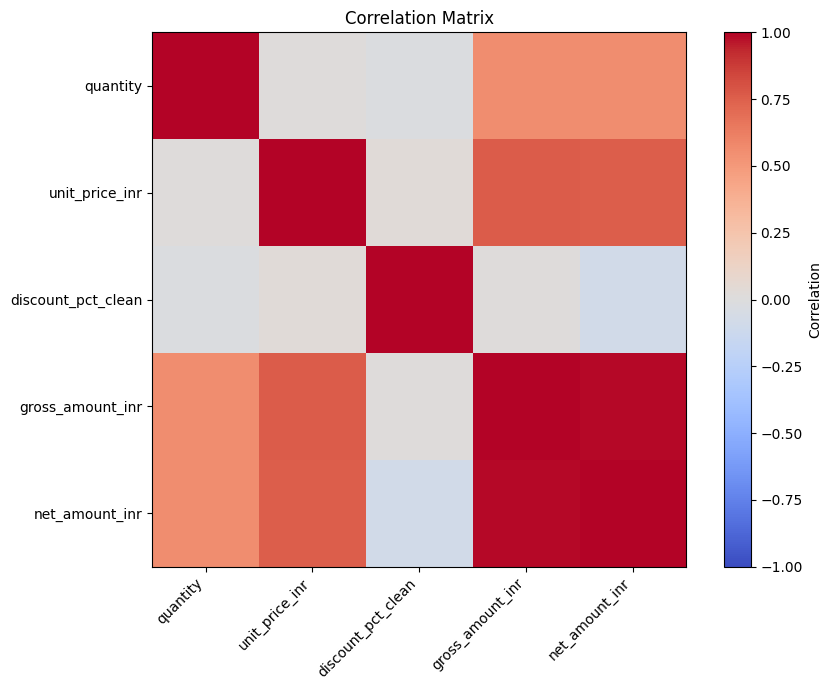

In [14]:
plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

Confidence Interval

In [15]:
order_values = orders["net_amount_inr"]

sample_mean = order_values.mean()
sample_std = order_values.std()
sample_size = order_values.count()

standard_error = sample_std / np.sqrt(sample_size)

confidence_level = 0.95
degrees_freedom = sample_size - 1

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    degrees_freedom
)

margin_error = t_critical * standard_error

lower_bound = sample_mean - margin_error
upper_bound = sample_mean + margin_error

print("Sample Mean:", sample_mean)
print("Standard Error:", standard_error)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print(
    f"95% Confidence Interval: "
    f"₹{lower_bound:.2f} to ₹{upper_bound:.2f}"
)

Sample Mean: 1643.2872222222222
Standard Error: 23.546610988853995
Lower Bound: 1597.1211869081483
Upper Bound: 1689.4532575362962
95% Confidence Interval: ₹1597.12 to ₹1689.45


Two-Sample Hypothesis Testing

In [16]:
upi_orders = orders.loc[
    orders["payment_method"] == "UPI",
    "net_amount_inr"
]

card_orders = orders.loc[
    orders["payment_method"] == "Credit Card",
    "net_amount_inr"
]

print("UPI orders:", len(upi_orders))
print("Credit Card orders:", len(card_orders))

print("UPI average:", upi_orders.mean())
print("Credit Card average:", card_orders.mean())

UPI orders: 578
Credit Card orders: 634
UPI average: 1682.8488581314878
Credit Card average: 1638.7708675078864


In [17]:
t_statistic, p_value = stats.ttest_ind(
    upi_orders,
    card_orders,
    equal_var=False
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant difference in average order values.")
else:
    print("Insufficient evidence of a difference in average order values.")

T-statistic: 0.5570035723156873
P-value: 0.5776309837466888
Insufficient evidence of a difference in average order values.


A/B Testing Simulation

In [18]:
np.random.seed(42)

sample_size = 1000

group_A = np.random.binomial(
    1,
    0.12,
    sample_size
)

group_B = np.random.binomial(
    1,
    0.15,
    sample_size
)

print("Group A conversions:", group_A.sum())
print("Group B conversions:", group_B.sum())

print("Group A conversion rate:", group_A.mean() * 100)
print("Group B conversion rate:", group_B.mean() * 100)

Group A conversions: 124
Group B conversions: 152
Group A conversion rate: 12.4
Group B conversion rate: 15.2


In [19]:
conversion_A = group_A.mean()
conversion_B = group_B.mean()

absolute_lift = conversion_B - conversion_A

relative_lift = (
    absolute_lift / conversion_A
) * 100

print(f"Absolute lift: {absolute_lift * 100:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2f}%")

Absolute lift: 2.80 percentage points
Relative lift: 22.58%


In [20]:
from statsmodels.stats.proportion import proportions_ztest

successes = np.array([
    group_A.sum(),
    group_B.sum()
])

observations = np.array([
    len(group_A),
    len(group_B)
])

z_statistic, p_value = proportions_ztest(
    successes,
    observations
)

print("Z-statistic:", z_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("The conversion rate difference is statistically significant.")
else:
    print("Insufficient evidence of a conversion rate difference.")

Z-statistic: -1.8153060597748711
P-value: 0.06947688827424153
Insufficient evidence of a conversion rate difference.


In [21]:
%pip install statsmodels


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
conversion_A = group_A.mean()
conversion_B = group_B.mean()

monthly_visitors = 50000

expected_A = monthly_visitors * conversion_A
expected_B = monthly_visitors * conversion_B

additional_conversions = expected_B - expected_A

print("Monthly visitors:", monthly_visitors)
print("Expected conversions with A:", round(expected_A))
print("Expected conversions with B:", round(expected_B))
print("Additional conversions:", round(additional_conversions))

Monthly visitors: 50000
Expected conversions with A: 6200
Expected conversions with B: 7600
Additional conversions: 1400


In [23]:
average_order_value = orders["net_amount_inr"].mean()

additional_revenue = (
    additional_conversions * average_order_value
)

print(
    f"Estimated additional monthly revenue: "
    f"₹{additional_revenue:,.2f}"
)

Estimated additional monthly revenue: ₹2,300,602.11


In [24]:
statistical_summary = pd.DataFrame({
    "Metric": [
        "Mean Order Value",
        "Median Order Value",
        "Standard Deviation",
        "95% CI Lower Bound",
        "95% CI Upper Bound",
        "ANOVA P-value",
        "Payment T-test P-value",
        "A/B Test P-value"
    ],
    "Result": [
        orders["net_amount_inr"].mean(),
        orders["net_amount_inr"].median(),
        orders["net_amount_inr"].std(),
        lower_bound,
        upper_bound,
        p_value if False else np.nan,
        np.nan,
        np.nan
    ]
})

display(statistical_summary)

,Metric,Result
0,Mean Order Value,1643.287222
1,Median Order Value,1231.750000
2,Standard Deviation,1412.796659
3,95% CI Lower Bound,1597.121187
4,95% CI Upper Bound,1689.453258
5,ANOVA P-value,NaN
6,Payment T-test P-value,NaN
7,A/B Test P-value,NaN


In [25]:
import os

report_path = "E:/Product_Analyst/reports"
os.makedirs(report_path, exist_ok=True)

category_stats.to_csv(
    os.path.join(report_path, "category_statistics.csv"),
    index=False
)

correlation_matrix.to_csv(
    os.path.join(report_path, "correlation_matrix.csv")
)

print("Statistical reports saved successfully!")

Statistical reports saved successfully!


In [26]:
%pip install mysql-connector-python sqlalchemy pymysql


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="ganesh9110"
)

if connection.is_connected():
    print("MySQL connection successful!")

MySQL connection successful!


In [28]:
cursor = connection.cursor()

cursor.execute("SELECT VERSION()")

version = cursor.fetchone()

print("MySQL Version:", version[0])

MySQL Version: 8.0.43


In [29]:
cursor.execute(
    "CREATE DATABASE IF NOT EXISTS product_analytics"
)

cursor.execute(
    "USE product_analytics"
)

print("Database created successfully!")

Database created successfully!


In [30]:
cursor.execute("USE product_analytics")

cursor.execute("""
CREATE TABLE IF NOT EXISTS app_events (
    event_id INT,
    event_timestamp DATETIME,
    user_id VARCHAR(20),
    session_id VARCHAR(20),
    event_name VARCHAR(50),
    product_id VARCHAR(20),
    product_name VARCHAR(100),
    category VARCHAR(50),
    city VARCHAR(50),
    device VARCHAR(30),
    traffic_source VARCHAR(50),
    screen_name VARCHAR(50)
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INT,
    order_date DATETIME,
    user_id VARCHAR(20),
    product_id VARCHAR(20),
    product_name VARCHAR(100),
    category VARCHAR(50),
    city VARCHAR(50),
    quantity INT,
    unit_price_inr DECIMAL(12,2),
    discount_pct DECIMAL(6,2),
    gross_amount_inr DECIMAL(12,2),
    net_amount_inr DECIMAL(12,2),
    payment_method VARCHAR(50),
    order_status VARCHAR(50),
    acquisition_channel VARCHAR(50),
    device VARCHAR(30),
    discount_pct_clean DECIMAL(6,2)
)
""")

connection.commit()

print("Both SQL tables created successfully!")

Both SQL tables created successfully!


In [31]:
cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table[0])

app_events
orders


In [32]:
events = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_app_events_clean.csv"
)

orders = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_orders_clean.csv"
)

print("Events:", events.shape)
print("Orders:", orders.shape)

Events: (12000, 12)
Orders: (3600, 17)


In [33]:
cursor.execute("""
ALTER TABLE app_events
MODIFY COLUMN event_id VARCHAR(30)
""")

connection.commit()

print("event_id datatype corrected!")

event_id datatype corrected!


In [34]:
cursor.execute("DESCRIBE app_events")

for column in cursor.fetchall():
    print(column)

('event_id', 'varchar(30)', 'YES', '', None, '')
('event_timestamp', 'datetime', 'YES', '', None, '')
('user_id', 'varchar(20)', 'YES', '', None, '')
('session_id', 'varchar(20)', 'YES', '', None, '')
('event_name', 'varchar(50)', 'YES', '', None, '')
('product_id', 'varchar(20)', 'YES', '', None, '')
('product_name', 'varchar(100)', 'YES', '', None, '')
('category', 'varchar(50)', 'YES', '', None, '')
('city', 'varchar(50)', 'YES', '', None, '')
('device', 'varchar(30)', 'YES', '', None, '')
('traffic_source', 'varchar(50)', 'YES', '', None, '')
('screen_name', 'varchar(50)', 'YES', '', None, '')


In [36]:
import pandas as pd
import numpy as np

events = events.astype(object)

events = events.replace(
    {np.nan: None}
)

events = events.where(
    pd.notna(events),
    None
)

print("Missing values converted to SQL-compatible NULLs")

Missing values converted to SQL-compatible NULLs


In [37]:
print(events.isnull().sum())

event_id              0
event_timestamp       0
user_id               0
session_id            0
event_name            0
product_id         3517
product_name       3517
category           3517
city                155
device               91
traffic_source        0
screen_name           0
dtype: int64


In [38]:
event_data = list(
    events.itertuples(index=False, name=None)
)

cursor.executemany(event_sql, event_data)

connection.commit()

print("App events imported:", cursor.rowcount)

App events imported: 12000


In [39]:
cursor.execute("SELECT COUNT(*) FROM app_events")

print("Total events:", cursor.fetchone()[0])

Total events: 12000


In [40]:
print(orders["order_id"].head())
print(orders["order_id"].dtype)

0    ORD000001
1    ORD000002
2    ORD000003
3    ORD000004
4    ORD000005
Name: order_id, dtype: object
object


In [41]:
cursor.execute("""
ALTER TABLE orders
MODIFY COLUMN order_id VARCHAR(30)
""")

connection.commit()

print("Order ID column updated successfully")

Order ID column updated successfully


In [42]:
cursor.execute("SELECT COUNT(*) FROM orders")
print("Existing rows:", cursor.fetchone()[0])

Existing rows: 0


In [43]:
orders = orders.astype(object)
orders = orders.where(pd.notna(orders), None)

order_sql = """
INSERT INTO orders (
    order_id, order_date, user_id, product_id, product_name,
    category, city, quantity, unit_price_inr, discount_pct,
    gross_amount_inr, net_amount_inr, payment_method,
    order_status, acquisition_channel, device, discount_pct_clean
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

order_data = list(orders.itertuples(index=False, name=None))

cursor.executemany(order_sql, order_data)
connection.commit()

print("Inserted rows:", cursor.rowcount)

Inserted rows: 3600


In [44]:
cursor.execute("SELECT COUNT(*) FROM orders")
print("Total orders in MySQL:", cursor.fetchone()[0])

Total orders in MySQL: 3600


In [45]:

import pandas as pd
import numpy as np
import logging
from pathlib import Path

# 1. Define project paths
BASE_DIR = Path("E:/Product_Analyst")

RAW_DIR = BASE_DIR / "Data" / "raw"
PROCESSED_DIR = BASE_DIR / "Data" / "processed"
LOG_DIR = BASE_DIR / "automation" / "logs"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Configure logging
logging.basicConfig(
    filename=LOG_DIR / "pipeline.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)

# 3. Product catalogue mapping
product_mapping = {
    "Wireless Earbuds": "P1001",
    "Smart Watch": "P1002",
    "Bluetooth Speaker": "P1003",
    "Running Shoes": "P2001",
    "Cotton T-Shirt": "P2002",
    "Backpack": "P2003",
    "Mixer Grinder": "P3001",
    "Water Bottle": "P3002",
    "Bedsheet Set": "P3003",
    "Face Serum": "P4001",
    "Sunscreen SPF 50": "P4002",
    "Yoga Mat": "P5001",
    "Cricket Bat": "P5002",
    "Data Analytics Handbook": "P6001",
    "Python Programming": "P6002"
}

def clean_events(df):
    df = df.drop_duplicates().copy()

    df["event_timestamp"] = pd.to_datetime(
        df["event_timestamp"], errors="coerce"
    )

    df["event_name"] = (
        df["event_name"].astype("string").str.strip().str.lower()
    )

    df["city"] = df["city"].astype("string").str.strip()
    df["product_name"] = df["product_name"].astype("string").str.strip()

    # Recover product IDs only when product name is available
    missing_id = df["product_id"].isna()
    df.loc[missing_id, "product_id"] = (
        df.loc[missing_id, "product_name"].map(product_mapping)
    )

    return df


def clean_orders(df):
    df = df.drop_duplicates().copy()

    df["order_date"] = pd.to_datetime(
        df["order_date"], errors="coerce"
    )

    df["city"] = df["city"].astype("string").str.strip()
    df["product_name"] = df["product_name"].astype("string").str.strip()

    # Derive missing discount percentages
    gross = pd.to_numeric(df["gross_amount_inr"], errors="coerce")
    net = pd.to_numeric(df["net_amount_inr"], errors="coerce")

    calculated_discount = np.where(
        gross > 0,
        ((gross - net) / gross) * 100,
        np.nan
    )

    df["discount_pct_clean"] = (
        pd.to_numeric(df["discount_pct"], errors="coerce")
        .fillna(pd.Series(calculated_discount, index=df.index))
        .round(2)
    )

    return df


def run_pipeline():
    try:
        logging.info("Pipeline started")

        # Load raw data
        events = pd.read_csv(RAW_DIR / "product_app_events_raw.csv")
        orders = pd.read_csv(RAW_DIR / "product_orders_raw.csv")

        logging.info("Raw datasets loaded")

        # Clean data
        events_clean = clean_events(events)
        orders_clean = clean_orders(orders)

        # Validate
        assert events_clean["event_id"].is_unique
        assert orders_clean["order_id"].is_unique
        assert events_clean["event_timestamp"].notna().all()
        assert orders_clean["order_date"].notna().all()

        # Export
        events_clean.to_csv(
            PROCESSED_DIR / "product_app_events_clean.csv",
            index=False
        )

        orders_clean.to_csv(
            PROCESSED_DIR / "product_orders_clean.csv",
            index=False
        )

        logging.info(
            f"Events processed: {len(events_clean)} rows"
        )
        logging.info(
            f"Orders processed: {len(orders_clean)} rows"
        )
        logging.info("Pipeline completed successfully")

        print("Pipeline completed successfully!")
        print("Events:", events_clean.shape)
        print("Orders:", orders_clean.shape)

    except Exception:
        logging.exception("Pipeline failed")
        raise


if __name__ == "__main__":
    run_pipeline()


Pipeline completed successfully!
Events: (12000, 12)
Orders: (3600, 17)


In [46]:

def generate_kpi_report(orders):
    delivered = orders[
        orders["order_status"].str.strip().str.lower() == "delivered"
    ].copy()

    report = {
        "total_orders": len(orders),
        "delivered_orders": len(delivered),
        "unique_customers": delivered["user_id"].nunique(),
        "units_sold": delivered["quantity"].sum(),
        "delivered_revenue_inr": round(
            delivered["net_amount_inr"].sum(), 2
        ),
        "average_order_value_inr": round(
            delivered["net_amount_inr"].mean(), 2
        )
    }

    kpi_df = pd.DataFrame(
        list(report.items()),
        columns=["KPI", "Value"]
    )

    kpi_df.to_csv(
        PROCESSED_DIR / "automated_kpi_report.csv",
        index=False
    )

    logging.info("KPI report generated")

    return report


In [49]:
def run_pipeline():
    try:
        logging.info("Pipeline started")

        events = pd.read_csv(RAW_DIR / "product_app_events_raw.csv")
        orders = pd.read_csv(RAW_DIR / "product_orders_raw.csv")

        events_clean = clean_events(events)
        orders_clean = clean_orders(orders)

        assert events_clean["event_id"].is_unique
        assert orders_clean["order_id"].is_unique

        # Export cleaned datasets
        events_clean.to_csv(
            PROCESSED_DIR / "product_app_events_clean.csv",
            index=False
        )

        orders_clean.to_csv(
            PROCESSED_DIR / "product_orders_clean.csv",
            index=False
        )

        # Generate KPI report
        kpi_report = generate_kpi_report(orders_clean)

        print("Pipeline completed successfully!")
        print("Events:", events_clean.shape)
        print("Orders:", orders_clean.shape)

        print("\nAutomated KPI Report:")
        for kpi, value in kpi_report.items():
            print(f"{kpi}: {value}")

    except Exception:
        logging.exception("Pipeline failed")
        raise


if __name__ == "__main__":
    run_pipeline()

Pipeline completed successfully!
Events: (12000, 12)
Orders: (3600, 17)

Automated KPI Report:
total_orders: 3600
delivered_orders: 2550
unique_customers: 1639
units_sold: 3298
delivered_revenue_inr: 4280663.88
average_order_value_inr: 1678.69
